# Demonstration of the merging of FCDP and 2D-S measurements

This notebook performs the merge and compares Re to Dongwei's calculations and compares Re, LWC, and extinction to the bulk properties dataset (cloud element averaged)

In [ ]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx

In [3]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40)

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:109: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


# Comparison to Donwei's Re calculations

<Axes: xlabel='datetime'>

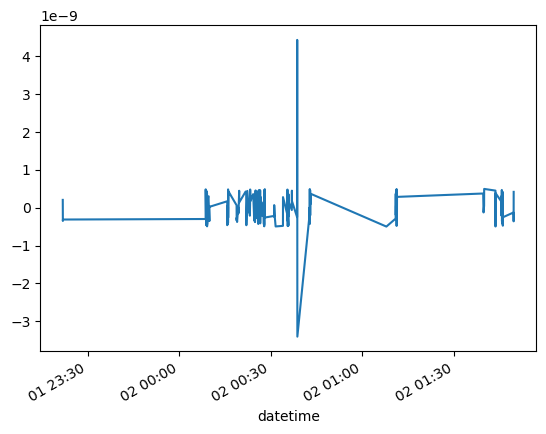

In [4]:
# Compare to dongwei's calculations of Re
dongwei_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'Dongwei' / 'P3_CAMP2Ex_database.csv'
dongwei = pd.read_csv(dongwei_file)
dongwei['Day_Of_Year'] = dongwei['Day_Of_Year_a']
compare_dw = pd.merge(p3, dongwei, on=['Time_Start','Day_Of_Year'])
compare_dw = cx.make_datetime(compare_dw, year_default=2019)
compare_dw = compare_dw.set_index('datetime')
(compare_dw['Re_x'] - compare_dw['Re_y']).plot()

# Comparison to Cloud Pass Average Properties

In [5]:
bulk_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
bulk_nav = cx.load_bulk(bulk_file, nav_file, CP_Type_accept=[1, 2, 3])
compare_bulk = pd.merge(p3, bulk_nav, on=['datetime'])
compare_bulk['Re_diff'] = compare_bulk['Re'] - compare_bulk['Reff_um']

start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')

# start_time = pd.to_datetime('2019-10-02 00:20:00')
# end_time = pd.to_datetime('2019-10-02 00:30:00')

# start_time = pd.to_datetime('2019-10-02 01:37:00')
# end_time = pd.to_datetime('2019-10-02 01:40:00')

# start_time = pd.to_datetime('2019-10-02 01:44:00')
# end_time = pd.to_datetime('2019-10-02 01:50:00')

# start_time = pd.to_datetime('2019-10-02 00:35:20')
# end_time = pd.to_datetime('2019-10-02 00:35:40')
# start_time = pd.to_datetime('2019-10-02 01:45:25')
# end_time = pd.to_datetime('2019-10-02 01:46:10')

p3_cloud = compare_bulk[
    (np.logical_or(compare_bulk['CP_Type'] == 3, compare_bulk['CP_Type'] == 1))
    & (compare_bulk.index > start_time)
    & (compare_bulk.index < end_time)
]

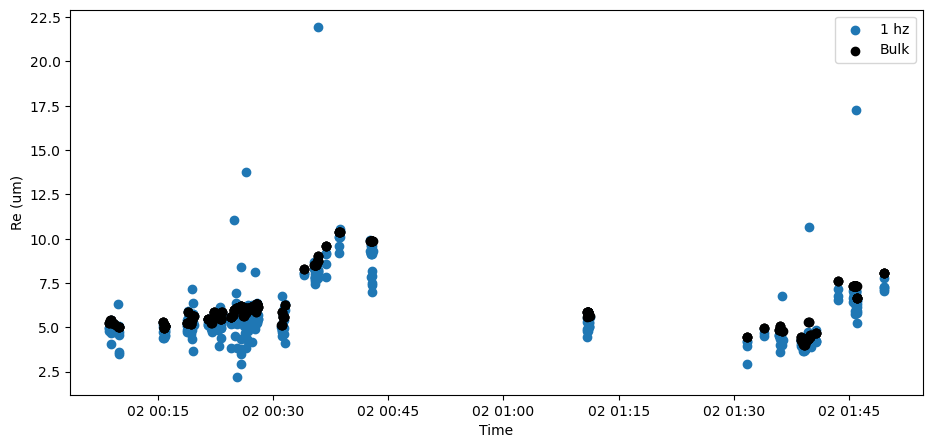

In [6]:
f, ax = plt.subplots(1, 1, figsize=(11,5))
s = ax.scatter(x=p3_cloud.index, y=p3_cloud['Re'],label='1 hz')# c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud.index, y=p3_cloud['Reff_um'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('Time')
ax.set_ylabel('Re (um)')
ax.legend()

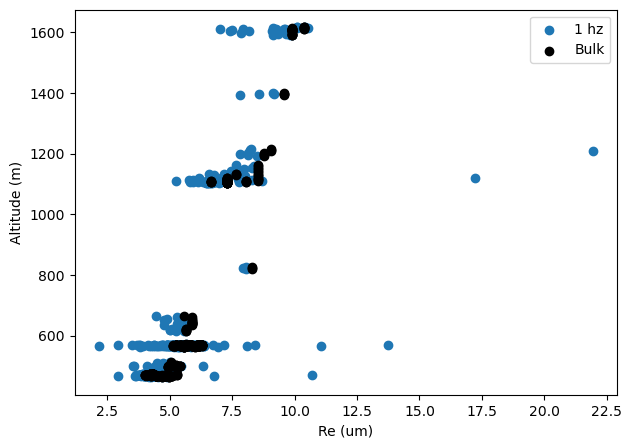

In [7]:
f, ax = plt.subplots(1, 1, figsize=(7,5))
s = ax.scatter(x=p3_cloud['Re'], y=p3_cloud['GPS_Altitude_x'],label='1 hz')#, c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud['Reff_um'], y=p3_cloud['GPS_Altitude_x'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('Re (um)')
ax.set_ylabel('Altitude (m)')
ax.legend()

In [8]:
pct_below1 = 100*np.sum(np.abs(p3_cloud['Re_diff']) < 1.0) / len(np.abs(p3_cloud['Re_diff']))
print(f'{pct_below1:.2f}% of 1 hz Re are within 1 um of the cloud average Re')

85.11% of 1 hz Re are within 1 um of the cloud average Re


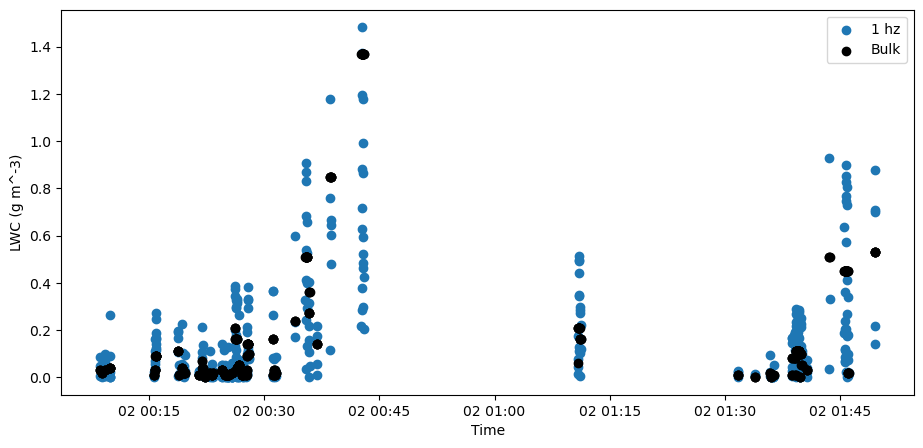

In [9]:
f, ax = plt.subplots(1, 1, figsize=(11,5))
s = ax.scatter(x=p3_cloud.index, y=p3_cloud['LWC_gm3_x'],label='1 hz')# c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud.index, y=p3_cloud['LWC_gm3_y'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('Time')
ax.set_ylabel('LWC (g m^-3)')
ax.legend()

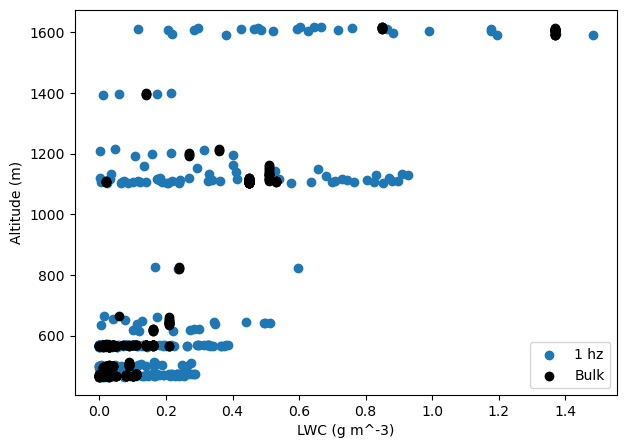

In [10]:
f, ax = plt.subplots(1, 1, figsize=(7,5))
s = ax.scatter(x=p3_cloud['LWC_gm3_x'], y=p3_cloud['GPS_Altitude_x'],label='1 hz')#, c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud['LWC_gm3_y'], y=p3_cloud['GPS_Altitude_x'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('LWC (g m^-3)')
ax.set_ylabel('Altitude (m)')
ax.legend()

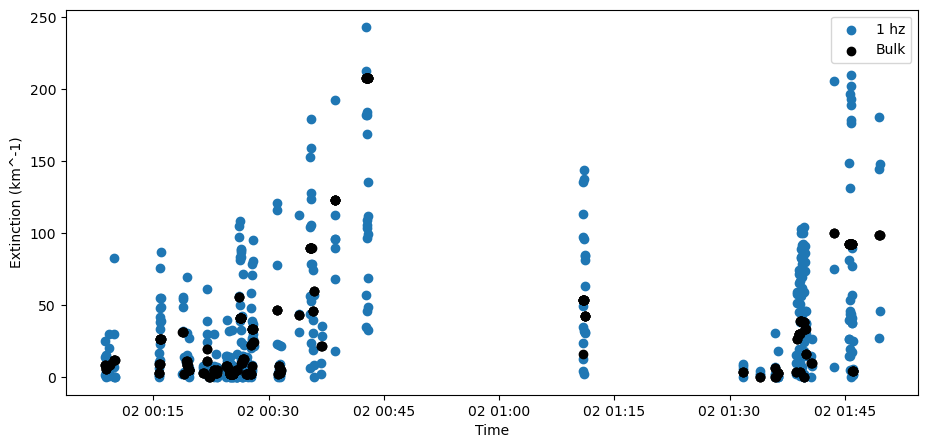

In [11]:
f, ax = plt.subplots(1, 1, figsize=(11,5))
s = ax.scatter(x=p3_cloud.index, y=p3_cloud['ext_km_x'],label='1 hz')# c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud.index, y=p3_cloud['ext_km_y'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('Time')
ax.set_ylabel('Extinction (km^-1)')
ax.legend()

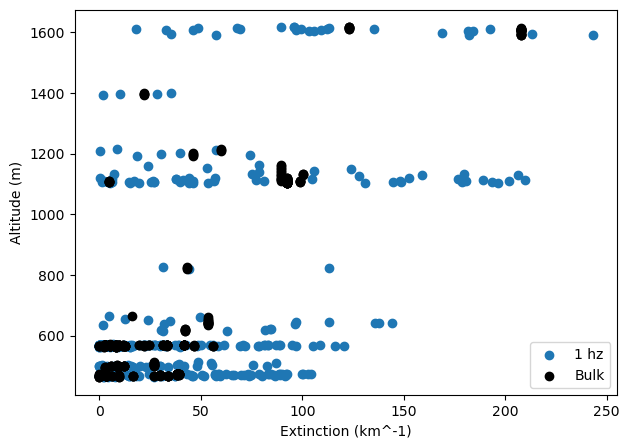

In [12]:
f, ax = plt.subplots(1, 1, figsize=(7,5))
s = ax.scatter(x=p3_cloud['ext_km_x'], y=p3_cloud['GPS_Altitude_x'],label='1 hz')#, c=np.log(p3_cloud['irregularCNT']), label='1 hz')
ax.scatter(x=p3_cloud['ext_km_y'], y=p3_cloud['GPS_Altitude_x'], c='k', label='Bulk')
# plt.colorbar(s, ax=ax)
ax.set_xlabel('Extinction (km^-1)')
ax.set_ylabel('Altitude (m)')
ax.legend()